# End-to-End KPI Framework for E-Commerce Operations (SQL)

**Dataset:** [Olist Brazilian E-Commerce](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) (7 of the 9 CSV files, as the task asks).


In [23]:
import os
import re
import sqlite3

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)

DATA_DIR = "data"
IMG_DIR = "images"
DB_PATH = "olist_kpi.db"
os.makedirs(IMG_DIR, exist_ok=True)


BLUE = "#2a78d6"
ORANGE = "#eb6834"
GREY = "#52514e"

## 1. Load the queries from `queries.sql`


In [24]:
def load_queries(path="queries.sql"):
    text = open(path, encoding="utf-8").read()
 
    parts = re.split(r"^-- (DDL|Q\d+[a-z]?|B\d+):.*$", text, flags=re.M)
    return {parts[i]: parts[i + 1].strip() for i in range(1, len(parts), 2)}

queries = load_queries()
print(list(queries))

['DDL', 'Q1a', 'Q1b', 'Q2', 'Q2b', 'Q2c', 'Q3', 'Q3b', 'Q4', 'Q5', 'Q6', 'Q7', 'Q8', 'Q9', 'Q10', 'B2', 'B3', 'B4', 'B5']


## 2. Create the database and load the 7 tables

The tables are created with the DDL from `queries.sql` (with primary keys), then pandas only inserts the rows (`if_exists="append"`), so the table design stays mine and not pandas'.

| Table | Primary key |
|---|---|
| customers | customer_id |
| sellers | seller_id |
| category_translation | product_category_name |
| products | product_id |
| orders | order_id |
| order_items | (order_id, order_item_id) |
| order_reviews | (review_id, order_id), because review_id alone repeats in the data |

In [25]:
if os.path.exists(DB_PATH):
    os.remove(DB_PATH)          

conn = sqlite3.connect(DB_PATH)
conn.executescript(queries["DDL"])

csv_files = {
    "customers":            "olist_customers_dataset.csv",
    "sellers":              "olist_sellers_dataset.csv",
    "category_translation": "product_category_name_translation.csv",
    "products":             "olist_products_dataset.csv",
    "orders":               "olist_orders_dataset.csv",
    "order_items":          "olist_order_items_dataset.csv",
    "order_reviews":        "olist_order_reviews_dataset.csv",
}

for table, file_name in csv_files.items():
    df = pd.read_csv(os.path.join(DATA_DIR, file_name))
    df.to_sql(table, conn, if_exists="append", index=False)
    print(f"{table:<22} {len(df):>7} rows loaded")


fk = conn.execute('''
    SELECT "table", parent, COUNT(*) AS bad_rows
    FROM pragma_foreign_key_check()
    GROUP BY "table", parent
''').fetchall()
print("\nforeign key violations:", fk)



conn.executescript(queries["Q2"])
print("view v_base created")

customers                99441 rows loaded
sellers                   3095 rows loaded
category_translation        71 rows loaded
products                 32951 rows loaded
orders                   99441 rows loaded
order_items             112650 rows loaded
order_reviews            99224 rows loaded

foreign key violations: [('products', 'category_translation', 13)]
view v_base created



## 3. Q1 - Row counts and orders -> order_items cardinality

In [26]:
display(pd.read_sql(queries["Q1a"], conn))
pd.read_sql(queries["Q1b"], conn)

,table_name,row_count
0,orders,99441
1,order_items,112650
2,products,32951
3,order_reviews,99224
4,sellers,3095
5,customers,99441
6,category_translation,71


,orders,order_items,avg_items_per_order_all,avg_items_per_order_with_items,orders_with_0_items,orders_with_1_item,orders_with_2plus_items,max_items_in_one_order
0,99441,112650,1.133,1.142,775,88863,9803,21


## 4. Q2 - Analytical base view `v_base` and join audit


In [27]:
display(pd.read_sql(queries["Q2b"], conn))
pd.read_sql(queries["Q2c"], conn).T.rename(columns={0: "count"})

,step,join_step,join_type,rows_after,orders_after
0,1,delivered orders,filter,96478,96478
1,2,+ order_items,INNER,110197,96478
2,3,+ products,LEFT,110197,96478
3,4,+ category_translation,LEFT,110197,96478
4,5,+ reviews (1 row per order) = v_base,LEFT,110197,96478


,count
delivered_orders_dropped_by_inner_items,0
items_without_product_row,0
items_with_no_category,1537
items_with_untranslated_category,22
delivered_orders_without_review,646
delivered_orders_with_2plus_reviews,525


## 5. Q3 - Revenue reconciliation (the most important step)

Revenue computed several ways:
- **(a)** `SUM(price)` directly on `order_items` (all statuses, and delivered only)
- **(b1)** `SUM(price)` on a **naive** join that uses the raw `order_reviews` table
- **(b2)** `SUM(price)` on `v_base`

In [28]:
pd.read_sql(queries["Q3"], conn)

,method,revenue,n_rows,diff_vs_a_delivered
0,"(a) order_items, all statuses",13591643.70,NaN,370145.59
1,"(a) order_items, delivered only",13221498.11,110197.0,0.00
2,(b1) naive join with raw reviews,13279836.59,110840.0,58338.48
3,"(b2) v_base, reviews 1 row per order",13221498.11,110197.0,0.00


In [29]:

pd.read_sql(queries["Q3b"], conn)

,n_reviews,delivered_orders,true_revenue,revenue_after_naive_join,extra_revenue
0,1,95307,13051910.86,13051910.86,0.00
1,2,521,57827.06,115654.12,57827.06
2,3,4,255.71,767.13,511.42


**Result:**
- The delivered-only standalone sum is **13,221,498.11 BRL**. `v_base` gives exactly the same number (difference 0.00), so the base view is not inflated.
- The naive join gives **13,279,836.59 BRL**, which is **+58,338.48 BRL** too much. It also has 110,840 rows instead of 110,197 (643 extra rows).
- **Cause:** `order_reviews` is one-to-many with `orders`. 521 delivered orders have 2 reviews and 4 have 3, so every item of those orders is repeated 2 or 3 times. Q3b shows the extra revenue exactly: 57,827.06 + 511.42 = 58,338.48.
- **Fix:** collapse reviews to one row per order (`GROUP BY order_id`, `AVG(review_score)`) *before* the join, as done inside `v_base`.
- The 13.59M figure (all statuses) is higher than 13.22M only because of the `delivered` filter (370,145.59 BRL comes from shipped, canceled and other statuses). That gap is a filter difference, not a join error.

## 6. Q4 - Core KPIs (delivered orders only)

In [30]:
pd.read_sql(queries["Q4"], conn)

,orders,total_revenue,aov,avg_delivery_days,avg_review_score
0,96478,13221498.11,137.04,12.56,4.156


## 7. Q5 - KPIs by category (SQL GROUP BY)

In [31]:
q5 = pd.read_sql(queries["Q5"], conn)
print(f"{len(q5)} categories")
q5.head(15)

74 categories


,category,order_count,total_revenue,aov,avg_delivery_days,avg_review_score
0,health_beauty,8647,1233131.72,142.61,12.08,4.229
1,watches_gifts,5495,1166176.98,212.23,12.81,4.121
2,bed_bath_table,9272,1023434.76,110.38,12.99,3.999
3,sports_leisure,7530,954852.55,126.81,12.24,4.228
4,computers_accessories,6530,888724.61,136.10,13.17,4.081
5,furniture_decor,6307,711927.69,112.88,13.07,4.058
6,housewares,5743,615628.69,107.20,11.09,4.194
7,cool_stuff,3559,610204.10,171.45,12.38,4.217
8,auto,3810,578966.65,151.96,12.33,4.146
9,toys,3804,471286.48,123.89,11.73,4.238


## 8. Q6 - KPIs by month

In [32]:
q6 = pd.read_sql(queries["Q6"], conn)
q6

,purchase_month,order_count,total_revenue,aov,avg_delivery_days,avg_review_score
0,2016-09,1,134.97,134.97,54.81,1.000
1,2016-10,265,40325.11,152.17,19.60,4.011
2,2016-12,1,10.90,10.90,4.69,5.000
3,2017-01,750,111798.36,149.06,12.65,4.199
4,2017-02,1653,234223.40,141.70,13.17,4.203
5,2017-03,2546,359198.85,141.08,12.95,4.187
6,2017-04,2303,340669.68,147.92,14.92,4.138
7,2017-05,3546,489338.25,138.00,11.32,4.238
8,2017-06,3135,421923.37,134.58,12.01,4.223
9,2017-07,3872,481604.52,124.38,11.59,4.258


2016-09 and 2016-12 have only 1 order each, so their averages are not meaningful. Real volume starts in 2017-01.

## 9. Q7 and Q8 - Top / bottom 5 categories (HAVING >= 100 orders)

In [33]:
q7 = pd.read_sql(queries["Q7"], conn)
q7

,segment,category,order_count,total_revenue
0,top 5,health_beauty,8647,1233131.72
1,top 5,watches_gifts,5495,1166176.98
2,top 5,bed_bath_table,9272,1023434.76
3,top 5,sports_leisure,7530,954852.55
4,top 5,computers_accessories,6530,888724.61
5,bottom 5,books_technical,256,18702.23
6,bottom 5,food_drink,221,14942.88
7,bottom 5,fashion_male_clothing,106,10452.33
8,bottom 5,fashion_underwear_beach,117,9305.95
9,bottom 5,christmas_supplies,125,8737.84


In [34]:
q8 = pd.read_sql(queries["Q8"], conn)
q8

,segment,category,order_count,avg_review_score
0,top 5,books_general_interest,496,4.535
1,top 5,food_drink,221,4.446
2,top 5,books_technical,256,4.427
3,top 5,luggage_accessories,1019,4.370
4,top 5,food,441,4.327
5,bottom 5,fixed_telephony,212,3.967
6,bottom 5,home_confort,392,3.887
7,bottom 5,audio,348,3.839
8,bottom 5,fashion_male_clothing,106,3.819
9,bottom 5,office_furniture,1254,3.643


## 10. Q9 - Seller KPIs ranked with RANK()

In [35]:
q9 = pd.read_sql(queries["Q9"], conn)
print(f"{len(q9)} sellers with delivered orders")
q9.head(10)

2970 sellers with delivered orders


,revenue_rank,seller_id,seller_city,seller_state,order_count,total_revenue,avg_review_score,avg_delivery_days,revenue_share_pct,cumulative_share_pct
0,1,4869f7a5dfa277a7dca6462dcf3b52b2,guariba,SP,1124,226987.93,4.151,15.06,1.717,1.72
1,2,53243585a1d6dc2643021fd1853d8905,lauro de freitas,BA,348,217940.44,4.194,13.43,1.648,3.37
2,3,4a3ca9315b744ce9f8e9374361493884,ibitinga,SP,1772,196882.12,3.853,14.49,1.489,4.85
3,4,fa1c13f2614d7b5c4749cbc52fecda94,sumare,SP,578,190917.14,4.373,13.35,1.444,6.30
4,5,7c67e1448b00f6e969d365cea6b010ab,itaquaquecetuba,SP,973,186570.05,3.496,22.34,1.411,7.71
5,6,7e93a43ef30c4f03f38b393420bc753a,barueri,SP,319,165981.49,4.365,11.31,1.255,8.96
6,7,da8622b14eb17ae2831f4ac5b9dab84a,piracicaba,SP,1311,159816.87,4.179,11.19,1.209,10.17
7,8,7a67c85e85bb2ce8582c35f2203ad736,sao paulo,SP,1145,139658.69,4.275,11.20,1.056,11.23
8,9,1025f0e2d44d7041d6cf58b6550e0bfa,sao paulo,SP,910,138208.56,4.009,12.39,1.045,12.28
9,10,955fee9216a65b617aa5c0531780ce60,sao paulo,SP,1261,131836.71,4.201,10.77,0.997,13.27


## 11. Q10 - Delivery days vs review score per category, and correlation

In [36]:
q10 = pd.read_sql(queries["Q10"], conn)

r = q10["avg_delivery_days"].corr(q10["avg_review_score"])   # Pearson
r_without_outlier = (q10[q10["category"] != "office_furniture"]
                     [["avg_delivery_days", "avg_review_score"]]
                     .corr().iloc[0, 1])

print(f"categories in the correlation: {len(q10)}")
print(f"Pearson r (avg delivery days vs avg review score): {r:.3f}")
print(f"Pearson r without office_furniture:                {r_without_outlier:.3f}")
q10.head(10)

categories in the correlation: 52
Pearson r (avg delivery days vs avg review score): -0.576
Pearson r without office_furniture:                -0.414


,category,order_count,avg_delivery_days,avg_review_score
0,office_furniture,1254,20.64,3.643
1,fashion_shoes,235,15.73,4.275
2,christmas_supplies,125,15.37,4.114
3,fashion_underwear_beach,117,14.00,4.009
4,computers,177,13.91,4.224
5,home_appliances_2,227,13.89,4.150
6,furniture_living_room,414,13.86,4.071
7,consoles_games,1018,13.77,4.178
8,home_confort,392,13.71,3.887
9,garden_tools,3448,13.63,4.181


**Interpretation:** r is about **-0.58**, a moderate negative relationship: categories that deliver more slowly tend to get lower review scores.
`office_furniture` is the clearest case (20.6 days, score 3.64). Without it the relationship is weaker but still negative (r ≈ -0.41), so the pattern does not rest on one category.
This is a category-level correlation (52 categories), so it shows a link, not a proof that delivery time causes the score.

## 12. Charts

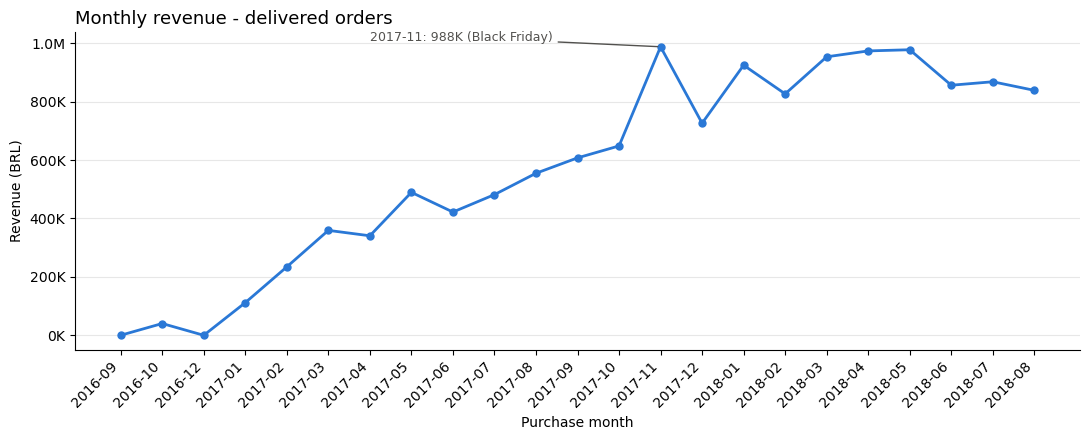

In [37]:
# Chart 1 - monthly revenue trend
fig, ax = plt.subplots(figsize=(11, 4.5))
q6.plot(x="purchase_month", y="total_revenue", ax=ax, color=BLUE, linewidth=2,
        marker="o", markersize=5, legend=False)

ax.set_title("Monthly revenue - delivered orders", fontsize=13, loc="left")
ax.set_xlabel("Purchase month")
ax.set_ylabel("Revenue (BRL)")
ax.set_xticks(range(len(q6)))
ax.set_xticklabels(q6["purchase_month"], rotation=45, ha="right")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M" if v >= 1e6 else f"{v/1e3:.0f}K"))
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)

peak = q6["total_revenue"].idxmax()
ax.annotate(f"{q6.loc[peak, 'purchase_month']}: {q6.loc[peak, 'total_revenue']/1e3:,.0f}K (Black Friday)",
            xy=(peak, q6.loc[peak, "total_revenue"]), xytext=(peak - 7, q6.loc[peak, "total_revenue"] * 1.02),
            fontsize=9, color=GREY, arrowprops=dict(arrowstyle="-", color=GREY))

plt.tight_layout()
plt.savefig(f"{IMG_DIR}/monthly_revenue_trend.png", dpi=150)
plt.show()

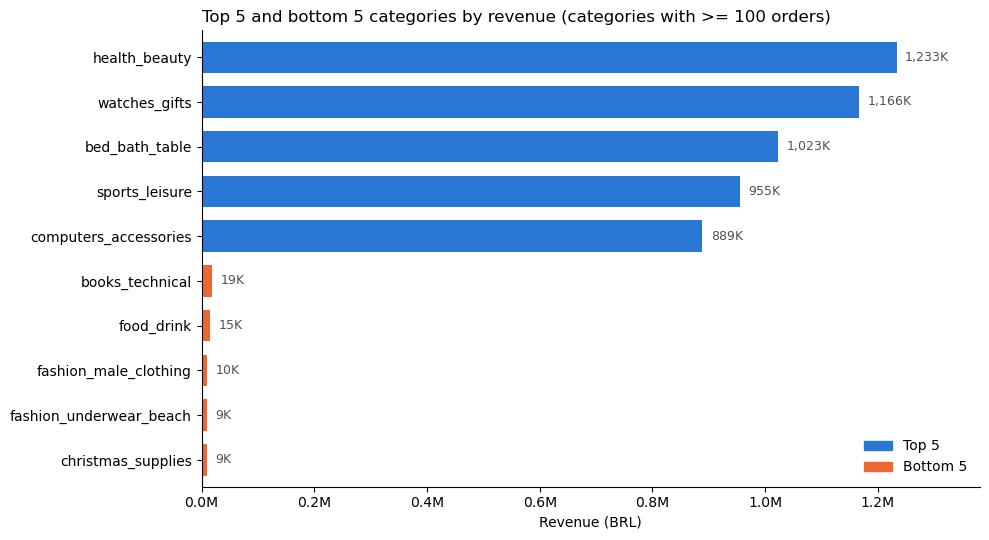

In [38]:
# Chart 2 - top 5 and bottom 5 categories by revenue (from Q7)
chart = q7.sort_values("total_revenue")
colors = [BLUE if s == "top 5" else ORANGE for s in chart["segment"]]

fig, ax = plt.subplots(figsize=(10, 5.5))
chart.plot(kind="barh", x="category", y="total_revenue", ax=ax, color=colors, legend=False, width=0.7)

for i, v in enumerate(chart["total_revenue"]):
    ax.text(v + 15000, i, f"{v/1e3:,.0f}K", va="center", fontsize=9, color=GREY)

ax.set_title("Top 5 and bottom 5 categories by revenue (categories with >= 100 orders)", fontsize=12, loc="left")
ax.set_xlabel("Revenue (BRL)")
ax.set_ylabel("")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M"))
ax.set_xlim(0, chart["total_revenue"].max() * 1.12)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=BLUE), plt.Rectangle((0, 0), 1, 1, color=ORANGE)],
          labels=["Top 5", "Bottom 5"], loc="lower right", frameon=False)

plt.tight_layout()
plt.savefig(f"{IMG_DIR}/top_bottom_categories_revenue.png", dpi=150)
plt.show()

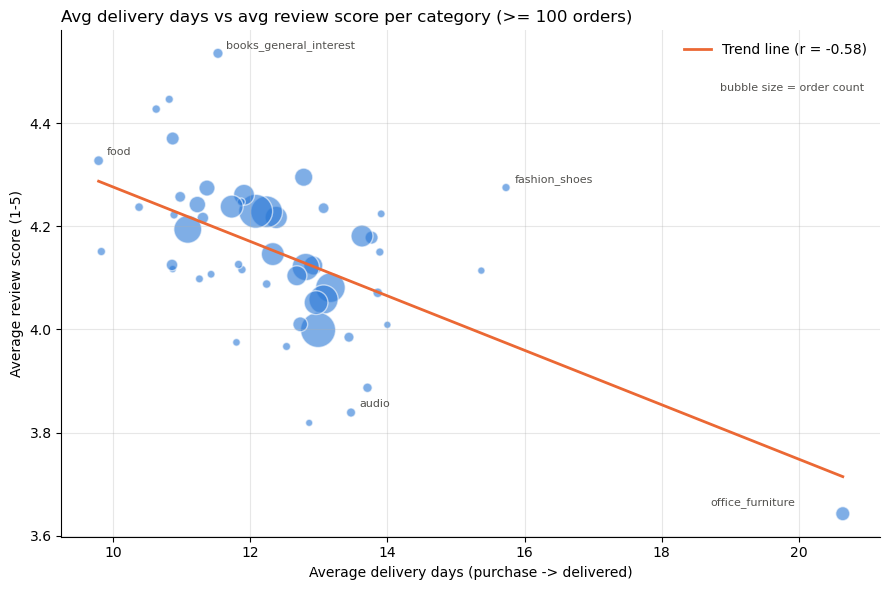

In [39]:
# Chart 3 - delivery days vs review score per category, with a trend line (from Q10)
slope, intercept = np.polyfit(q10["avg_delivery_days"], q10["avg_review_score"], 1)
x_line = np.linspace(q10["avg_delivery_days"].min(), q10["avg_delivery_days"].max(), 100)

fig, ax = plt.subplots(figsize=(9, 6))
q10.plot(kind="scatter", x="avg_delivery_days", y="avg_review_score", ax=ax,
         s=q10["order_count"] / 15 + 20, color=BLUE, alpha=0.6, edgecolor="white")
ax.plot(x_line, slope * x_line + intercept, color=ORANGE, linewidth=2,
        label=f"Trend line (r = {r:.2f})")

labels = {"office_furniture": (-95, 6), "books_general_interest": (6, 4),
          "fashion_shoes": (6, 4), "audio": (6, 4), "food": (6, 4)}
for name, offset in labels.items():
    row = q10[q10["category"] == name].iloc[0]
    ax.annotate(name, (row["avg_delivery_days"], row["avg_review_score"]),
                xytext=offset, textcoords="offset points", fontsize=8, color=GREY)

ax.set_title("Avg delivery days vs avg review score per category (>= 100 orders)", fontsize=12, loc="left")
ax.set_xlabel("Average delivery days (purchase -> delivered)")
ax.set_ylabel("Average review score (1-5)")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.text(0.98, 0.88, "bubble size = order count", transform=ax.transAxes, ha="right", fontsize=8, color=GREY)

plt.tight_layout()
plt.savefig(f"{IMG_DIR}/delivery_vs_review_scatter.png", dpi=150)
plt.show()

## 13. Bonus



**B2 - On-time delivery rate**

In [40]:
pd.read_sql(queries["B2"], conn)

,delivery_status,orders,share_pct,avg_delivery_days,avg_review_score
0,on time,89936,93.22,11.00,4.291
1,late,6534,6.77,33.95,2.272
2,no delivery date,8,0.01,NaN,4.500


**B3 - Anti-join: orders that never received a review**

In [41]:
pd.read_sql(queries["B3"], conn)

,order_status,orders,orders_without_review,share_without_review_pct
0,ALL,99441,768,0.77
1,delivered,96478,646,0.67
2,shipped,1107,75,6.78
3,canceled,625,20,3.20
4,unavailable,609,14,2.30
5,invoiced,314,5,1.59
6,processing,301,6,1.99
7,created,5,2,40.00
8,approved,2,0,0.00


**B4 - Freight-to-revenue ratio per category (flag: freight >= 25% of revenue)**

In [42]:
b4 = pd.read_sql(queries["B4"], conn)
print(f"flagged categories: {(b4['flag'] != 'ok').sum()} of {len(b4)}")
b4.head(12)

flagged categories: 8 of 52


,category,order_count,total_revenue,total_freight,freight_to_revenue_pct,flag
0,christmas_supplies,125,8737.84,3190.91,36.52,shipping erodes margin
1,signaling_and_security,138,21315.05,6477.54,30.39,shipping erodes margin
2,electronics,2517,155043.93,45679.16,29.46,shipping erodes margin
3,food_drink,221,14942.88,4394.89,29.41,shipping erodes margin
4,furniture_living_room,414,67350.70,17694.37,26.27,shipping erodes margin
5,kitchen_dining_laundry_garden_furniture,241,45531.98,11540.99,25.35,shipping erodes margin
6,drinks,287,21529.84,5441.27,25.27,shipping erodes margin
7,office_furniture,1254,268154.31,67057.05,25.01,shipping erodes margin
8,food,441,28731.15,7063.53,24.58,ok
9,furniture_decor,6307,711927.69,168402.23,23.65,ok


**B5 - Each category's share of monthly revenue (window function)**

In [43]:
b5 = pd.read_sql(queries["B5"], conn)


top5 = q7.loc[q7["segment"] == "top 5", "category"].tolist()
b5[b5["category"].isin(top5)].pivot(index="purchase_month", columns="category", values="share_pct")[top5]

category,health_beauty,watches_gifts,bed_bath_table,sports_leisure,computers_accessories
purchase_month,,,,,
2016-10,8.53,6.72,1.19,4.99,1.66
2017-01,11.06,7.23,3.40,8.24,3.51
2017-02,9.42,4.69,6.65,6.67,4.83
2017-03,7.14,6.93,6.99,7.09,7.82
2017-04,6.50,6.85,7.07,6.75,5.39
2017-05,9.47,7.48,6.68,6.97,9.15
2017-06,7.51,6.48,8.01,7.60,8.58
2017-07,7.11,7.00,13.04,7.60,7.93
2017-08,8.84,6.52,10.20,7.32,6.10


- **B2:** 93.22% of delivered orders arrived on or before the estimated date. The 6.77% late orders score only 2.27 on average.
- **B3:** 768 of 99,441 orders (0.77%) never got a review. Among delivered orders it is 646 (0.67%). Shipped orders have the highest share (6.78%), because many of them were never delivered.
- **B4:** 8 of 52 categories pay freight equal to 25% or more of their item revenue.
- **B5:** `health_beauty` grew from about 6-9% of monthly revenue in 2017 to 14.24% in 2018-08. `computers_accessories` peaked at 12.12% in 2018-02 and then fell to about 4.8%.

## 14. Five operational insights

1. **Late delivery is the biggest driver of bad reviews (B2).** 6.77% of delivered orders (6,534) arrived after the estimated date. Their average score is **2.27**, against **4.29** for on-time orders, and they took 33.95 days on average. *Action:* alert the customer and the seller as soon as an order is at risk of missing the estimate, and give extra buffer to the estimate on slow routes.
2. **Peak season breaks delivery, and ratings follow (Q6).** Orders jumped from 4,478 (2017-10) to 7,289 (2017-11, Black Friday). Delivery time went from 11.86 to 15.16 days and the score fell from 4.21 to 3.99. Feb-Mar 2018 was the worst period (16.95 / 16.30 days, scores 3.88 / 3.81). By 2018-08 delivery was down to 7.73 days with a 4.31 score. *Action:* add carrier capacity before November and the post-holiday months.
3. **Slower categories get lower scores (Q10, Q8).** Across 52 categories r = -0.58. `office_furniture` is the worst case: 20.64 days, score **3.64** (lowest in Q8), 1,254 orders. *Action:* treat bulky categories as a separate logistics flow (dedicated carriers, realistic estimates).
4. **A few sellers carry a lot of revenue, and some of them hurt the experience (Q9).** The top 10 of 2,970 sellers bring **13.27%** of revenue. Seller #5 (`7c67e144...`, 973 orders) averages 22.34 delivery days and a 3.50 score, and seller #3 (`4a3ca931...`, 1,772 orders) scores 3.85. *Action:* key-account management with delivery SLAs for top sellers, starting with these two.
5. **Shipping eats the margin in some categories (B4).** 8 categories pay freight equal to 25% or more of item revenue. `electronics` is the largest of them (2,517 orders, 29.46%), and `office_furniture` is also flagged (25.01%). *Action:* free-shipping thresholds, bundling small items, or renegotiated freight rates for these categories.

In [44]:
conn.close()